In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import files

uploaded = files.upload()

Saving 20260522_OBGA.BingHP_shutterstock_394633729_bing.jpg to 20260522_OBGA.BingHP_shutterstock_394633729_bing.jpg


In [3]:
# Get the uploaded file name
filename = list(uploaded.keys())[0]

# Load the image
image = cv2.imread(filename)

# Check if image was loaded
if image is None:
    raise ValueError("Image could not be loaded.")

# Convert BGR to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Convert to grayscale
gray_image = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

print("Image loaded successfully!")
print("File name:", filename)
print("Image shape:", image.shape)

Image loaded successfully!
File name: 20260522_OBGA.BingHP_shutterstock_394633729_bing.jpg
Image shape: (3110, 4665, 3)


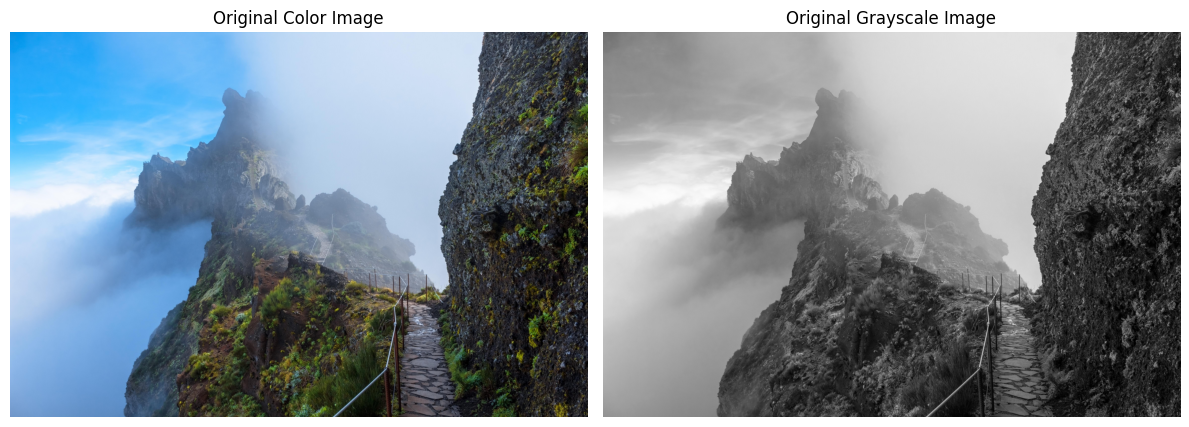

In [4]:
plt.figure(figsize=(12, 5))

# Original color image
plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Color Image")
plt.axis("off")

# Grayscale image
plt.subplot(1, 2, 2)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()

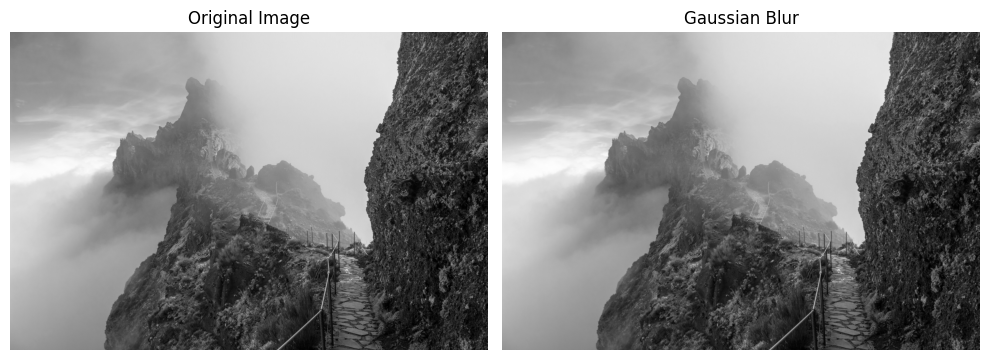

In [5]:
# Apply Gaussian Blur
gaussian = cv2.GaussianBlur(gray_image, (5, 5), 0)

# Display result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Blur")
plt.axis("off")

plt.tight_layout()
plt.show()

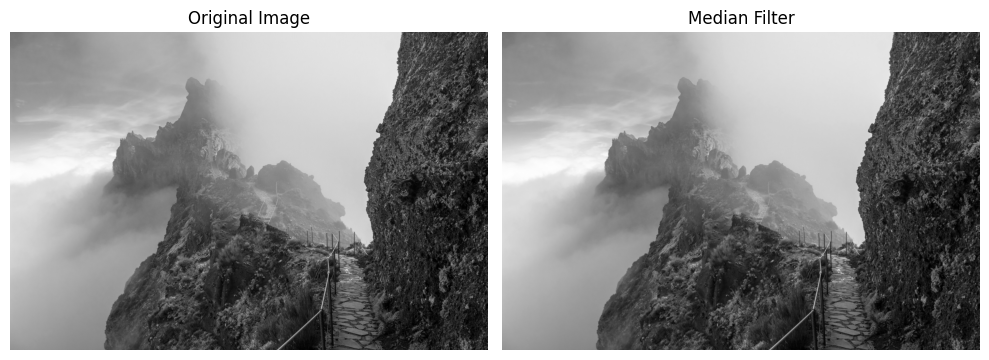

In [6]:
# Apply Median Filter
median = cv2.medianBlur(gray_image, 5)

# Display result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(median, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

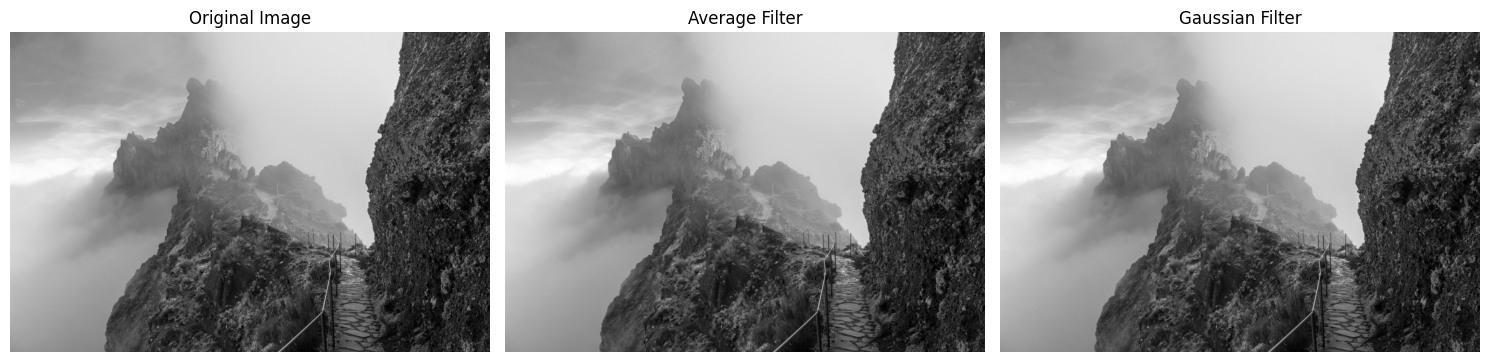

In [7]:
# Apply Average / Mean Filter
average = cv2.blur(gray_image, (5, 5))

# Display comparison
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(average, cmap="gray")
plt.title("Average Filter")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

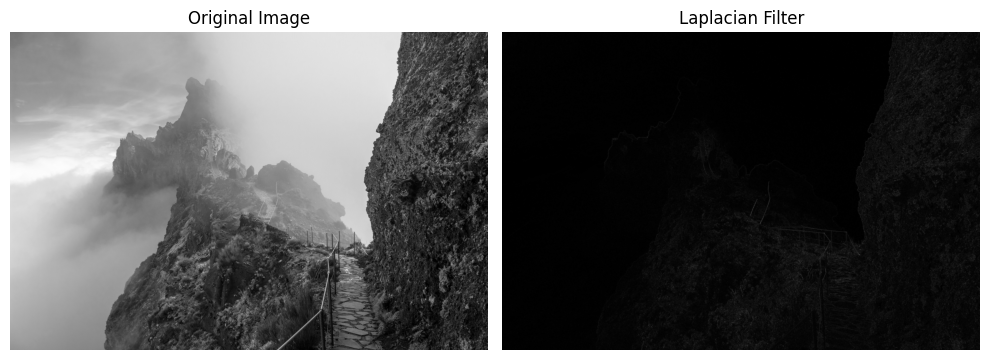

In [8]:
# Apply Laplacian Filter
laplacian = cv2.Laplacian(gray_image, cv2.CV_64F)

# Convert result to 8-bit image
laplacian = cv2.convertScaleAbs(laplacian)

# Display result
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian Filter")
plt.axis("off")

plt.tight_layout()
plt.show()

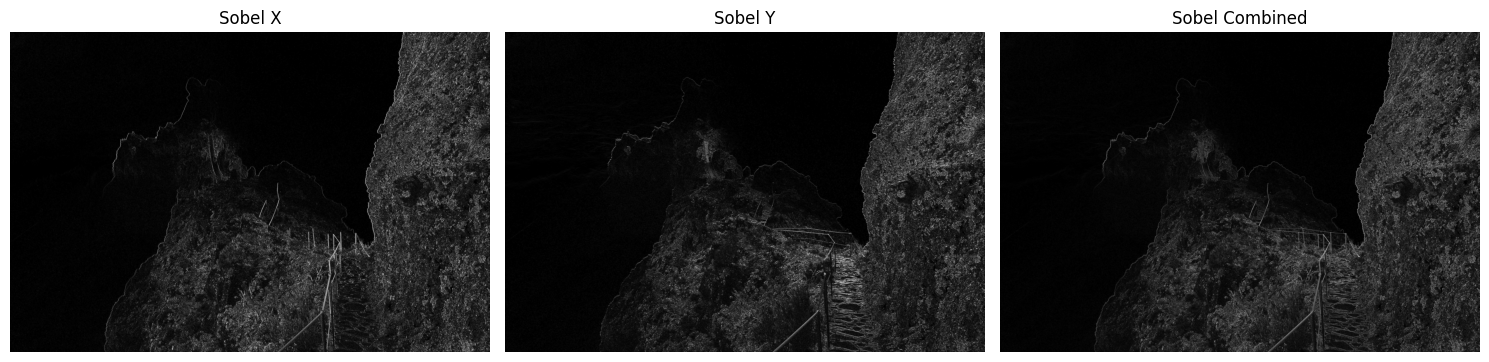

In [9]:
# Sobel in X direction
sobel_x = cv2.Sobel(gray_image, cv2.CV_64F, 1, 0, ksize=3)
sobel_x = cv2.convertScaleAbs(sobel_x)

# Sobel in Y direction
sobel_y = cv2.Sobel(gray_image, cv2.CV_64F, 0, 1, ksize=3)
sobel_y = cv2.convertScaleAbs(sobel_y)

# Combine Sobel X and Y
sobel_combined = cv2.addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0)

# Display results
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(sobel_x, cmap="gray")
plt.title("Sobel X")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sobel_y, cmap="gray")
plt.title("Sobel Y")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sobel_combined, cmap="gray")
plt.title("Sobel Combined")
plt.axis("off")

plt.tight_layout()
plt.show()

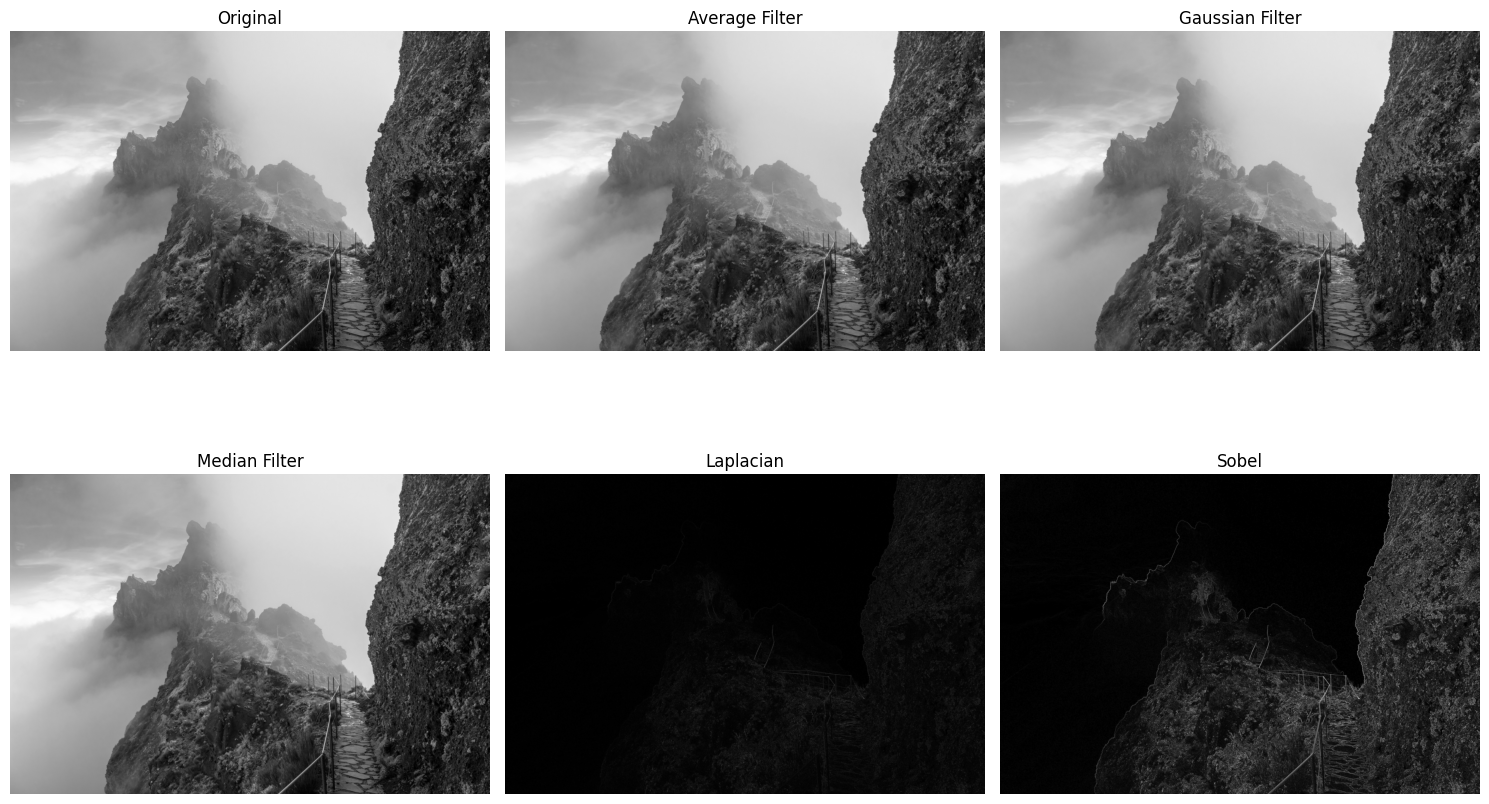

In [10]:
plt.figure(figsize=(15, 10))

plt.subplot(2, 3, 1)
plt.imshow(gray_image, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(2, 3, 2)
plt.imshow(average, cmap="gray")
plt.title("Average Filter")
plt.axis("off")

plt.subplot(2, 3, 3)
plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")

plt.subplot(2, 3, 4)
plt.imshow(median, cmap="gray")
plt.title("Median Filter")
plt.axis("off")

plt.subplot(2, 3, 5)
plt.imshow(laplacian, cmap="gray")
plt.title("Laplacian")
plt.axis("off")

plt.subplot(2, 3, 6)
plt.imshow(sobel_combined, cmap="gray")
plt.title("Sobel")
plt.axis("off")

plt.tight_layout()
plt.show()

In [11]:
import time

# Average Filter
start = time.perf_counter()
cv2.blur(gray_image, (5, 5))
average_time = time.perf_counter() - start

# Gaussian Filter
start = time.perf_counter()
cv2.GaussianBlur(gray_image, (5, 5), 0)
gaussian_time = time.perf_counter() - start

# Median Filter
start = time.perf_counter()
cv2.medianBlur(gray_image, 5)
median_time = time.perf_counter() - start

# Laplacian Filter
start = time.perf_counter()
cv2.Laplacian(gray_image, cv2.CV_64F)
laplacian_time = time.perf_counter() - start

# Sobel Filter
start = time.perf_counter()
cv2.Sobel(gray_image, cv2.CV_64F, 1, 0, ksize=3)
sobel_time = time.perf_counter() - start

print("Computational Performance")
print("-------------------------")
print(f"Average Filter : {average_time:.6f} seconds")
print(f"Gaussian Filter: {gaussian_time:.6f} seconds")
print(f"Median Filter  : {median_time:.6f} seconds")
print(f"Laplacian      : {laplacian_time:.6f} seconds")
print(f"Sobel          : {sobel_time:.6f} seconds")

Computational Performance
-------------------------
Average Filter : 0.015532 seconds
Gaussian Filter: 0.031261 seconds
Median Filter  : 0.035027 seconds
Laplacian      : 0.092761 seconds
Sobel          : 0.090632 seconds


ques 10 .  Interpret the results and discuss the applications of spatial filtering in real-world
computer vision systems

The experiment successfully implemented spatial filtering techniques using OpenCV. Low-pass filters such as Average, Gaussian, and Median were useful for image smoothing and noise reduction. High-pass filters such as Laplacian and Sobel successfully enhanced and detected edges and fine image details.

Spatial filtering is useful in:

Medical imaging — noise reduction and enhancement of anatomical structures.
Surveillance — image enhancement and object detection.
Remote sensing — enhancement of satellite and aerial images.
Autonomous vehicles — road, lane, and object boundary detection.

Q1. What is spatial filtering? How is it used in digital image processing?

Spatial filtering is a digital image processing technique in which the value of a pixel is modified using the values of its neighboring pixels. A small matrix called a kernel or filter mask is moved over the image to perform mathematical operations on the pixels.

Spatial filtering is used for:

Image smoothing
Noise reduction
Edge detection
Image sharpening
Feature enhancement

The basic process is:

Input Image

     ↓
   Kernel

     ↓
Pixel Neighborhood Processing

     ↓
Filtered Image

Q2. Differentiate between Low-Pass Filters and High-Pass Filters with suitable examples.

A Low-Pass Filter allows low-frequency components of an image to remain and reduces high-frequency components. It is mainly used for smoothing and noise reduction.

Examples:

Average Filter
Gaussian Filter
Median Filter

A High-Pass Filter emphasizes high-frequency components such as edges, fine details, and sudden intensity changes.

Examples:

Sobel Filter
Laplacian Filter

Q3. Compare Average Filter, Gaussian Filter, and Median Filter based on their working principles and applications.

The Average Filter replaces a pixel with the average of the neighboring pixels. It is simple and useful for general image smoothing, but it can blur edges.

The Gaussian Filter uses a weighted average in which pixels closer to the center have greater importance. It provides smooth noise reduction and usually preserves image structure better than the average filter.

The Median Filter replaces a pixel with the median value of its neighboring pixels. It is especially effective for removing salt-and-pepper noise while preserving edges.

Q4. Why is the Median Filter particularly effective for removing salt-and-pepper noise?

Salt-and-pepper noise contains isolated pixels with very high or very low intensity values, usually 255 and 0.

The median filter sorts the neighboring pixel values and selects the middle value. Extreme values have very little effect on the median.

For example:

10    11    12
11   255    13
12    13    14

After sorting:

10, 11, 11, 12, 12, 13, 13, 14, 255

The median is 12.

Q5. Explain the role of convolution kernels in spatial filtering.

A convolution kernel is a small matrix of numerical values used to process pixels and their neighboring pixels.

The kernel moves across the image. At each location, the kernel values are combined with the corresponding image pixels to calculate a new pixel value.

For example, an average filter uses:

$$ K=\frac{1}{9} \begin{bmatrix} 1&1&1\\ 1&1&1\\ 1&1&1 \end{bmatrix} $$

The kernel determines what operation is performed on the image.

Image

  ↓

Kernel moves over pixels

  ↓

Mathematical operation

  ↓

New pixel value

  ↓

Filtered image

Different kernels are used for different purposes, such as smoothing, sharpening, and edge detection.



Q6. What is the purpose of the Sobel and Laplacian operators in edge detection?

Answer:

The Sobel operator is used to detect edges by calculating the intensity gradient of an image in horizontal and vertical directions.

It uses:

Sobel X for one gradient direction
Sobel Y for the other gradient direction

The two results can be combined to obtain the overall edge information.

The Laplacian operator detects rapid changes in intensity using the second derivative of the image. It highlights edges and fine details in multiple directions.

Q7. Why are filtering operations considered an essential preprocessing step in computer vision?

Answer:

Real-world images often contain noise, unwanted details, illumination variations, and other disturbances.

Filtering improves the input image before further processing.

It can:

Reduce noise

Smooth the image

Remove unwanted variations

Improve edge detection

Enhance important features

Improve object detection accuracy


A typical process is:

Raw Image

    ↓

Filtering

    ↓

Noise Reduction

    ↓

Feature Extraction

    ↓

Object Detection

    ↓
    
Recognition

Q8. Discuss the trade-off between image smoothing and edge preservation during filtering.

Answer:

Smoothing reduces noise, but excessive smoothing can also remove important edges and fine details.

If very little smoothing is applied:


Less smoothing

      ↓

More noise

      ↓

False or unwanted edges

If too much smoothing is applied:

More smoothing

      ↓

Less noise

      ↓

Blurred edges

      ↓

Loss of fine details


Therefore, the filter and kernel size must be selected carefully.

The objective is:

Reduce Noise + Preserve Important Edges

Q9. Mention four real-world applications where spatial filtering techniques are widely used.

Answer:

1. Medical Imaging

Spatial filtering is used in X-ray, CT, and MRI images to reduce noise and enhance important anatomical structures.

2. Surveillance Systems

Filtering improves video and camera images and helps in object and face detection.

3. Remote Sensing

Satellite and aerial images are filtered to remove noise and enhance geographical features.

4. Autonomous Vehicles

Filtering is used before lane detection, road-boundary detection, pedestrian detection, and object recognition.

Other applications include robotics, industrial inspection, microscopy, and document image processing.

Q10. Compare spatial domain filtering with frequency domain filtering in terms of implementation and practical applications.

Answer:

Spatial domain filtering works directly on the pixels of an image. It generally uses kernels and convolution operations.

Frequency domain filtering first converts the image into its frequency representation, usually using the Fourier Transform. Filtering is then performed on the frequency components before converting the result back into an image.

Spatial Domain:

Image

  ↓

Kernel

  ↓

Convolution

  ↓

Filtered Image

Frequency Domain:

Image

  ↓

Fourier Transform

  ↓

Frequency Spectrum

  ↓

Frequency Filter

  ↓

Inverse Transform

  ↓
  
Filtered Image

Spatial filtering is commonly used for smoothing, sharpening, and edge detection.

Frequency domain filtering is particularly useful for frequency analysis and removing periodic noise.